# Solubility as a continuous value

The series so far scored every model on how many bits it carries about a compound's **tier**. That framing came from a misreading of the floor: [01_prep_and_analysis.ipynb](01_prep_and_analysis.ipynb) put a single measurement's information at about 1.5 bits, and the tiers notebook turned that into four classes. But the floor is a continuous-channel quantity, $I(\mu;Y) = h(Y) - h(e)$, and binning paid for it twice: the repeat-measurement benchmark on four tiers is 0.96 bits, half a bit below the floor, before any model ran, and the tier boundaries themselves were arbitrary (tuning them bought nothing over quantiles).

This notebook redoes the comparison on the value itself. Each model predicts logS; the prediction becomes a density over the measured value by the replicate noise density from the prep notebook — the same symmetrized kernel density the floor was computed with — widened by the model's own error $\tau$ and mixed with a share $\varepsilon$ of a wide gross-error component, both chosen on the validation side exactly as $\lambda$ was for the tiers. The score is

$$\text{information} = h(Y) - \text{cross-entropy of the predictive density on the held-out votes}$$

in bits, vote-weighted so every compound counts once. Three things fall out that the tiers could not give. The ceiling is clean: a model that predicted the consensus exactly and reported the noise density as its spread would score the floor. The predictive width *is* the error bar: $\tau$ is how much error the model adds beyond measurement noise, and the central intervals of the predictive density are the bars a user would be quoted. And nothing upstream changes: identity, votes, flags, features and splits are all target-agnostic.

Same models as before, so the two framings can be set side by side: Delaney's equation and its least-squares refit, additive models (now `ExplainableBoostingRegressor`) and random forests on ESOL's four inputs and on the 152 descriptors, on the random, cluster and learned splits. PySR, GOSDT and CORELS are not rerun here: PySR is slow and the other two are classifiers, so they stay in the tier appendix.

In [1]:
import itertools
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from interpret.glassbox import ExplainableBoostingRegressor
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

RDLogger.DisableLog("rdApp.warning")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import GRID, METRICS_C, Noise, calibrate_c, corrected_se, entropy_c, formatted, noise_residuals, score_c  # noqa: E402

measurements = pd.read_csv(ROOT / "data" / "aqsoldb_measurements.csv")  # one row per vote, from the prep notebook
values = measurements[~measurements["flagged"]].reset_index(drop=True)  # flagged votes set aside, as for the tiers
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")  # one row per compound
learned = pd.read_csv(ROOT / "data" / "aqsoldb_splits_ls.csv", index_col="InChIKey").reindex(splits.index)
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]
LS_SPLITS = [c for c in learned.columns if c.startswith("ls_") and c[3:].isdigit()]
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}
all_splits = splits.join(learned[LS_SPLITS])

compound = splits.index.get_indexer(values["InChIKey"])  # vote row -> compound
assert (compound >= 0).all(), "a vote's compound is missing from the splits"
y = values["Solubility"].to_numpy()
n_compounds = len(splits)
votes_per = np.bincount(compound, minlength=n_compounds)
w = 1 / votes_per[compound]  # every compound counts once
repeated = votes_per > 1  # compounds with 2+ unflagged votes

# ESOL's four inputs, computed as in 04_features.ipynb.
mols = [Chem.MolFromSmiles(s) for s in values.groupby("InChIKey")["SMILES"].first().reindex(splits.index)]
assert all(mols), "a SMILES failed to parse"
esol = pd.DataFrame(
    {
        "MolLogP": [Descriptors.MolLogP(m) for m in mols],
        "MolWt": [Descriptors.MolWt(m) for m in mols],
        "NumRotatableBonds": [Descriptors.NumRotatableBonds(m) for m in mols],
        "AromaticProportion": [sum(a.GetIsAromatic() for a in m.GetAtoms()) / m.GetNumHeavyAtoms() for m in mols],
    },
    index=splits.index,
)
assert np.allclose(esol["MolLogP"], features["MolLogP"]), "MolLogP differs from the features hand-off"
DESCRIPTORS = f"RDKit, one per group ({features.shape[1]})"
INPUTS = {"ESOL (4)": esol, DESCRIPTORS: features}


def sides(split: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    side = all_splits[split].to_numpy()
    train, validation, test = side == "train", side == "validation", side == "test"
    assert train.any() and validation.any() and test.any(), f"{split}: a side has no rows"
    return train, validation, test


def test_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()


noise = Noise(noise_residuals(measurements))  # the prep notebook's residuals: votes around the mean of their compound's other votes
H_ALL = entropy_c(y, w)
FLOOR = H_ALL - noise.entropy
FLOOR_REPEATED = entropy_c(y[repeated[compound]], w[repeated[compound]]) - noise.entropy  # the 2+-vote compounds have their own spread
print(
    f"{len(values)} votes ({int(measurements['flagged'].sum())} flagged set aside), {n_compounds} compounds, {repeated.sum()} with 2+ votes; "
    f"{len(CV_SPLITS)} random, {len(CLUSTER_SPLITS)} cluster, {len(LS_SPLITS)} learned splits\n"
    f"h(Y) = {H_ALL:.3f} bits, h(e) = {noise.entropy:.3f} bits -> floor {FLOOR:.3f} bits over all compounds, {FLOOR_REPEATED:.3f} over those with 2+ votes "
    f"(the prep notebook's 1.56 used the consensus values convolved with the noise; here h(Y) is of the votes themselves)"
)

12013 votes (84 flagged set aside), 9946 compounds, 1580 with 2+ votes; 10 random, 10 cluster, 5 learned splits
h(Y) = 3.248 bits, h(e) = 1.824 bits -> floor 1.424 bits over all compounds, 1.522 over those with 2+ votes (the prep notebook's 1.56 used the consensus values convolved with the noise; here h(Y) is of the votes themselves)


## The noise density, and what a prediction's error bar looks like

The noise density $e$ is a single genuine measurement's deviation from its compound's consensus — the prep notebook's residuals, symmetrized and smoothed. A model's prediction $\hat y$ differs from the consensus by its own error; if that error is roughly normal with SD $\tau$, the measured vote scatters around $\hat y$ as $e \ast \mathcal{N}(0,\tau^2)$. A small share $\varepsilon$ of a wide component (SD 2.4 logS, the scale flagged votes sit at) covers the votes that are gross errors the flagging could not catch — single-vote and two-vote compounds carry the error rate as a prior — and plays the role the shrinkage toward uniform played for the tiers: it bounds how much one wild vote can cost. Both are chosen on validation; $\tau = 0$ means the model adds no error the data can detect.

Below: the noise density on its own and widened by a few $\tau$, with the half-widths of the central 50% and 90% intervals. The $\tau = 0$ row is the irreducible error bar: no model can honestly quote a narrower one.

,50% half-width (logS),90% half-width (logS)
τ (logS),,
0.0,0.43,1.48
0.3,0.49,1.56
0.6,0.63,1.79
1.0,0.86,2.24


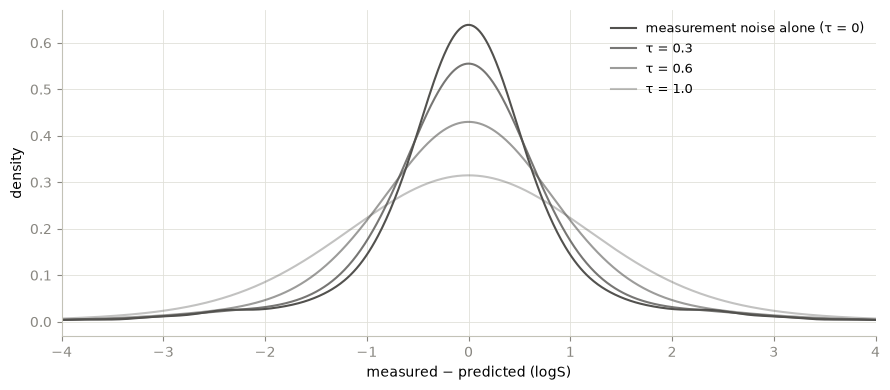

In [2]:
INK, MUTED, GRID_C, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SHOW_TAUS = [0.0, 0.3, 0.6, 1.0]


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID_C, lw=0.6)
    ax.set_axisbelow(True)


fig, ax = plt.subplots(figsize=(9, 4))
for tau, alpha in zip(SHOW_TAUS, np.linspace(1, 0.35, len(SHOW_TAUS))):
    ax.plot(GRID, noise.predictive(tau, 0), color=INK, alpha=alpha, lw=1.5, label=f"τ = {tau}" if tau else "measurement noise alone (τ = 0)")
ax.set_xlim(-4, 4)
ax.set_xlabel("measured − predicted (logS)")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=9)
style(ax)
fig.tight_layout()

pd.DataFrame(
    {"50% half-width (logS)": [noise.interval(t, 0, 0.5) for t in SHOW_TAUS], "90% half-width (logS)": [noise.interval(t, 0, 0.9) for t in SHOW_TAUS]},
    index=pd.Index(SHOW_TAUS, name="τ (logS)"),
).round(2)

## The repeat-measurement benchmark

For a compound with two or more votes, the best feature-free prediction of one vote is the mean of the others. Scored like any model — calibrated on the validation compounds, scored on the test compounds with 2+ votes — it is what "as good as measuring the compound again" means on this axis. It is not the ceiling: the other votes carry their own noise (which $\tau$ absorbs), so a model of the consensus could in principle beat it, and the floor above is the true limit.

In [3]:
sums = np.bincount(compound, weights=y, minlength=n_compounds)
others = np.where(votes_per[compound] > 1, (sums[compound] - y) / np.maximum(votes_per[compound] - 1, 1), np.nan)  # leave-one-out mean

benchmark_rows = []
for scheme, split_list in SCHEMES.items():
    for split in split_list:
        train, validation, test = sides(split)
        v, t = validation[compound] & repeated[compound], test[compound] & repeated[compound]
        tau, eps = calibrate_c(y[v], others[v], w[v], noise)
        benchmark_rows.append({"scheme": scheme, "split": split, **score_c(y[t], others[t], w[t], noise, tau, eps)})
benchmark = pd.DataFrame(benchmark_rows)
BENCHMARK = {scheme: benchmark[benchmark["scheme"] == scheme]["information (bits)"].mean() for scheme in SCHEMES}
by = benchmark.groupby("scheme", sort=False)[list(METRICS_C)]
spread = pd.DataFrame({s: by.get_group(s).apply(corrected_se, n_splits=len(l), test_to_train=test_to_train(l)) if s != "learning to split" else by.get_group(s).std() for s, l in SCHEMES.items()}).T
print(f"floor on the 2+-vote compounds: {FLOOR_REPEATED:.3f} bits")
(formatted(by.mean(), METRICS_C) + " ± " + formatted(spread, METRICS_C)).rename_axis("repeat measurement (test compounds with 2+ votes)")

floor on the 2+-vote compounds: 1.522 bits


,information (bits),RMSE (logS),MAE (logS),within 0.5 logS (%),τ (logS),ε
repeat measurement (test compounds with 2+ votes),,,,,,
random cross-validation,1.481 ± 0.060,1.050 ± 0.047,0.699 ± 0.034,57.1 ± 1.5,0.05 ± 0.04,0.05 ± 0.03
cluster cross-validation,1.478 ± 0.074,1.047 ± 0.049,0.699 ± 0.031,57.1 ± 1.6,0.06 ± 0.05,0.04 ± 0.02
learning to split,0.974 ± 0.081,1.239 ± 0.026,0.834 ± 0.022,50.6 ± 1.9,0.02 ± 0.04,0.03 ± 0.04


## The models, on three kinds of split

Each is trained on a split's train side (every vote of the train compounds, each compound weighted once), its $(\tau, \varepsilon)$ chosen on the validation side, and scored on the test side — all test compounds, and those with 2+ votes. The pair counts for the EBMs are the ones the additive notebook chose on validation for the tiers (5 on ESOL's inputs, 20 on the descriptors), not re-tuned here. Alongside the information: RMSE and MAE of the point prediction, the share of votes within 0.5 logS of it, and the calibrated $\tau$ and $\varepsilon$. Also recorded per fit: how often the measured vote falls inside the predictive density's central 50% and 90% intervals, which is the check that the error bars mean what they say.

In [4]:
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)  # as in 04_features.ipynb
EBM_SETTINGS = dict(random_state=0, n_jobs=-1)  # InterpretML defaults otherwise
PAIRS = {"ESOL (4)": 5, DESCRIPTORS: 20}
DELANEY = {"MolLogP": -0.63, "MolWt": -0.0062, "NumRotatableBonds": 0.066, "AromaticProportion": -0.74}
delaney = (0.16 + sum(c * esol[k] for k, c in DELANEY.items())).to_numpy()
EQUATION_LENGTH = 14  # nodes of ESOL's form, as counted in 08_equations.ipynb

PREDICTORS = {"Delaney's equation (published)": ("published", "ESOL (4)"), "least squares refit of ESOL's form": ("least squares", "ESOL (4)")}
for inputs in INPUTS:
    PREDICTORS[f"EBM, main effects, {inputs}"] = (0, inputs)
    PREDICTORS[f"EBM, {PAIRS[inputs]} pairs, {inputs}"] = (PAIRS[inputs], inputs)
    PREDICTORS[f"random forest, {inputs}"] = ("forest", inputs)
FAMILY = {name: "equation" if isinstance(kind, str) and kind != "forest" else "random forest" if kind == "forest" else "EBM" for name, (kind, _) in PREDICTORS.items()}
SUBSETS = {"all test compounds": np.ones(n_compounds, bool), "test compounds with 2+ unflagged votes": repeated}


def fit(name: str, train: np.ndarray) -> tuple[np.ndarray, float]:
    # Point prediction of logS for every compound, and the numbers needed to write the model down.
    kind, inputs = PREDICTORS[name]
    x, rows = INPUTS[inputs], train[compound]
    if kind == "published":
        return delaney, EQUATION_LENGTH
    if kind == "least squares":
        fill = x[train].median()
        model = LinearRegression().fit(x.iloc[compound[rows]].fillna(fill), y[rows], sample_weight=w[rows])
        return model.predict(x.fillna(fill)), EQUATION_LENGTH
    if kind == "forest":
        model = RandomForestRegressor(**RF_SETTINGS).fit(x.to_numpy()[compound[rows]], y[rows], sample_weight=w[rows])
        return model.predict(x.to_numpy()), sum(t.tree_.n_leaves for t in model.estimators_)  # one number per leaf
    model = ExplainableBoostingRegressor(interactions=kind, **EBM_SETTINGS).fit(x.iloc[compound[rows]], y[rows], sample_weight=w[rows])
    return model.predict(x), sum(model.term_scores_[i].size for i in range(len(model.term_features_)))


def coverage(err: np.ndarray, weight: np.ndarray, tau: float, eps: float, level: float) -> float:
    return float(100 * (weight * (np.abs(err) <= noise.interval(tau, eps, level))).sum() / weight.sum())


started = time.time()
rows, predictions = [], {}  # predictions: (name, split) -> per-compound point prediction, for the plots
for name in PREDICTORS:
    for scheme, split_list in SCHEMES.items():
        for split in split_list:
            train, validation, test = sides(split)
            prediction, length = fit(name, train)
            predictions[name, split] = prediction
            v = validation[compound]
            tau, eps = calibrate_c(y[v], prediction[compound[v]], w[v], noise)
            for subset, mask in SUBSETS.items():
                t = (test & mask)[compound]
                err = y[t] - prediction[compound[t]]
                rows.append({"predictor": name, "scheme": scheme, "split": split, "subset": subset, "length": length,
                             **score_c(y[t], prediction[compound[t]], w[t], noise, tau, eps),
                             "inside 50% interval (%)": coverage(err, w[t], tau, eps, 0.5), "inside 90% interval (%)": coverage(err, w[t], tau, eps, 0.9)})
    print(f"{name}: {(time.time() - started) / 60:.0f} min")
held_out = pd.DataFrame(rows)

SHOWN = {**METRICS_C, "inside 50% interval (%)": 1, "inside 90% interval (%)": 1}
tables, means = {}, {}
for name in PREDICTORS:
    blocks = {}
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)[list(SHOWN)]
        if scheme == "learning to split":
            spread = by.std()
            blocks[f"{scheme} (mean ± SD)"] = formatted(by.mean(), SHOWN) + " ± " + formatted(spread, SHOWN)
        else:
            spread = by.apply(lambda g: g.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list)))
            blocks[f"{scheme} (mean ± SE)"] = formatted(by.mean(), SHOWN) + " ± " + formatted(spread, SHOWN)
        for subset in SUBSETS:
            means[name, scheme, subset] = (by.mean().loc[subset, "information (bits)"], spread.loc[subset, "information (bits)"])
    tables[name] = pd.concat(blocks, names=["split", "subset"])
pd.set_option("display.width", 250)
pd.concat(tables, names=["predictor"])[["information (bits)", "RMSE (logS)", "within 0.5 logS (%)", "τ (logS)", "ε", "inside 50% interval (%)", "inside 90% interval (%)"]]

Delaney's equation (published): 0 min


least squares refit of ESOL's form: 0 min


EBM, main effects, ESOL (4): 1 min


EBM, 5 pairs, ESOL (4): 3 min


random forest, ESOL (4): 3 min


/Users/kthrossell/working/mini-model-exploration/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


EBM, main effects, RDKit, one per group (152): 9 min


EBM, 20 pairs, RDKit, one per group (152): 20 min


random forest, RDKit, one per group (152): 27 min


information (bits)    RMSE (logS) within 0.5 logS (%)     τ (logS)            ε inside 50% interval (%)  \
predictor                                     split                                subset                                                                                                                                           
Delaney's equation (published)                random cross-validation (mean ± SE)  all test compounds                          0.270 ± 0.175  2.074 ± 0.111          30.8 ± 0.7  0.77 ± 0.02  0.19 ± 0.01              48.9 ± 0.9   
                                                                                   test compounds with 2+ unflagged votes     -0.373 ± 0.842  2.593 ± 0.304          28.4 ± 1.0  0.77 ± 0.02  0.19 ± 0.01              45.4 ± 0.8   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.265 ± 0.193  2.068 ± 0.132          30.8 ± 0.9  0.75 ± 0.02  0.20 ± 0.00              48.5 ± 1.3   
                                                                                   test compounds with 2+ unflagged votes     -0.538 ± 1.115  2.610 ± 0.381          28.6 ± 1.7  0.75 ± 0.02  0.20 ± 0.00              45.6 ± 2.7   
                                              learning to split (mean ± SD)        all test compounds                         -0.645 ± 0.232  2.591 ± 0.119          21.7 ± 1.0  0.70 ± 0.07  0.14 ± 0.05              32.4 ± 2.5   
                                                                                   test compounds with 2+ unflagged votes     -1.914 ± 1.462  3.455 ± 0.490          20.8 ± 2.0  0.70 ± 0.07  0.14 ± 0.05              32.3 ± 3.1   
least squares refit of ESOL's form            random cross-validation (mean ± SE)  all test compounds                          0.373 ± 0.136  1.784 ± 0.033          26.0 ± 0.7  1.18 ± 0.03  0.14 ± 0.03              50.0 ± 0.8   
                                                                                   test compounds with 2+ unflagged votes      0.346 ± 0.068  2.066 ± 0.106          25.0 ± 1.8  1.18 ± 0.03  0.14 ± 0.03              46.8 ± 2.1   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.358 ± 0.144  1.788 ± 0.066          26.0 ± 1.4  1.19 ± 0.06  0.13 ± 0.04              50.0 ± 2.6   
                                                                                   test compounds with 2+ unflagged votes      0.319 ± 0.097  2.075 ± 0.169          24.8 ± 1.9  1.19 ± 0.06  0.13 ± 0.04              46.6 ± 2.6   
                                              learning to split (mean ± SD)        all test compounds                         -0.261 ± 0.078  2.222 ± 0.109          18.2 ± 1.3  1.04 ± 0.09  0.10 ± 0.07              33.5 ± 1.7   
                                                                                   test compounds with 2+ unflagged votes     -0.649 ± 0.375  2.696 ± 0.318          19.8 ± 2.4  1.04 ± 0.09  0.10 ± 0.07              35.7 ± 4.2   
EBM, main effects, ESOL (4)                   random cross-validation (mean ± SE)  all test compounds                          0.836 ± 0.014  1.398 ± 0.021          34.9 ± 0.6  0.76 ± 0.02  0.08 ± 0.02              50.2 ± 1.1   
                                                                                   test compounds with 2+ unflagged votes      0.819 ± 0.043  1.544 ± 0.050          33.3 ± 1.4  0.76 ± 0.02  0.08 ± 0.02              48.6 ± 1.7   
                                              cluster cross-validation (mean ± SE) all test compounds                          0.827 ± 0.036  1.401 ± 0.018          34.3 ± 0.7  0.75 ± 0.02  0.08 ± 0.01              50.0 ± 0.7   
                                                                                   test compounds with 2+ unflagged votes      0.813 ± 0.062  1.537 ± 0.056          33.4 ± 1.8  0.75 ± 0.02  0.08 ± 0.01              48.6 ± 2.0   


**Reading the table.** The ceiling is now one number and everything sits under it. The repeat-measurement benchmark lands at 1.48 bits on both random and cluster splits, 97% of the floor on its own population (1.52): a second measurement is nearly as good as knowing the consensus, which is what the floor says it should be. The forest on the 152 descriptors carries 1.28 bits on random splits and 1.18 on cluster splits — 90% and 83% of the floor — and the additive models 1.19–1.21 and 1.10–1.13. The ordering of the models is the one the tiers gave; the distances have changed.

The equations fall much further on this axis than on the tiers: Delaney's published line carries 0.27 bits here against 0.60 on the tiers, and its standard error over splits is six times larger. The tiers were forgiving of large errors — any miss inside a tier was free, and a miss beyond was capped by the shrinkage $\lambda$ — while a density charges the equation's 2-logS root-mean-square error in full. A fifth of Delaney's predictive mass goes to the wide component ($\varepsilon = 0.2$): the calibration is telling us the published coefficients, fitted on 2,874 compounds with Daylight's logP, miss this dataset's extremes by more than noise. The least-squares refit of the same form halves the RMSE and barely improves the bits, because what the form cannot bend to is still charged.

The calibration check holds where it should: on random and cluster splits every model's 50% and 90% intervals contain 50% and 90% of the held-out votes, to within a point. On the learned splits they contain 65–80%, and every model's information is negative, as on the tiers: the hardest compounds are hard in a way their validation side does not show, so $\tau$ chosen there is too small. The repeat benchmark drops to 0.97 bits on the same compounds — they are also where measurements disagree most.

## Tiers against values: the same models on both axes

The tier information for these models comes from the front files the additive and equations notebooks wrote. The two axes are not the same bits — one is about a four-way label, the other about a value to the precision the noise allows — so the comparison that matters is each score against its own ceiling: the 0.96-bit repeat benchmark for the tiers, the floor for the values.

In [5]:
tier_front = pd.concat([pd.read_csv(f) for f in sorted((ROOT / "data").glob("aqsoldb_front_*.csv")) if "continuous" not in f.name], ignore_index=True)
tier_front = tier_front[(tier_front["subset"] == "all test compounds") & tier_front["model"].isin(PREDICTORS)].drop_duplicates(["model", "scheme"], keep="last")
TIER_BENCHMARK = 0.963

lengths = held_out[held_out["scheme"] == "random cross-validation"].groupby("predictor", sort=False)["length"].mean()
front = pd.DataFrame(
    [{"model": name, "family": FAMILY[name], "inputs": PREDICTORS[name][1], "scheme": scheme, "subset": subset,
      "information (bits)": means[name, scheme, subset][0], "spread": means[name, scheme, subset][1],
      "numbers to write it down": lengths[name], "readable": FAMILY[name] != "random forest"}
     for name in PREDICTORS for scheme in SCHEMES for subset in SUBSETS]
)
front.to_csv(ROOT / "data" / "aqsoldb_front_continuous.csv", index=False)

side_by_side = front[front["subset"] == "all test compounds"].merge(tier_front[["model", "scheme", "information (bits)"]], on=["model", "scheme"], how="left", suffixes=(" (values)", " (tiers)"))
side_by_side["share of floor (%)"] = 100 * side_by_side["information (bits) (values)"] / FLOOR
side_by_side["share of tier benchmark (%)"] = 100 * side_by_side["information (bits) (tiers)"] / TIER_BENCHMARK
comparison = side_by_side.pivot_table(index="model", columns="scheme", values=["information (bits) (values)", "information (bits) (tiers)", "share of floor (%)", "share of tier benchmark (%)"], sort=False)
comparison.reindex(list(PREDICTORS)).round({c: 1 if "share" in c[0] else 3 for c in comparison.columns})

information (bits) (values)                                            information (bits) (tiers)                                                 share of floor (%)                           \
scheme                                            random cross-validation cluster cross-validation learning to split    random cross-validation cluster cross-validation learning to split random cross-validation cluster cross-validation   
model                                                                                                                                                                                                                                         
Delaney's equation (published)                                      0.270                    0.265            -0.645                      0.595                    0.588            -0.451                    19.0                     18.6   
least squares refit of ESOL's form                                  0.373                    0.358            -0.261                      0.451                    0.436            -0.445                    26.2                     25.1   
EBM, main effects, ESOL (4)                                         0.836                    0.827            -0.323                      0.726                    0.714            -0.877                    58.7                     58.1   
EBM, 5 pairs, ESOL (4)                                              0.915                    0.894            -0.371                      0.808                    0.784            -1.046                    64.3                     62.8   
random forest, ESOL (4)                                             0.935                    0.891            -0.439                      0.769                    0.725            -1.258                    65.6                     62.6   
EBM, main effects, RDKit, one per group (152)                       1.191                    1.101            -0.251                      0.936                    0.895            -1.448                    83.6                     77.3   
EBM, 20 pairs, RDKit, one per group (152)                           1.213                    1.134            -0.267                      0.950                    0.907            -1.619                    85.2                     79.7   
random forest, RDKit, one per group (152)                           1.283                    1.179            -0.535                      1.009                    0.941            -0.609                    90.1                     82.8   

                                                                share of tier benchmark (%)                                             
scheme                                        learning to split     random cross-validation cluster cross-validation learning to split  
model                                                                                                                                   
Delaney's equation (published)                            -45.3                        61.8                     61.1             -46.8  
least squares refit of ESOL's form                        -18.3                        46.8                     45.2             -46.2  
EBM, main effects, ESOL (4)                               -22.7                        75.4                     74.1             -91.1  
EBM, 5 pairs, ESOL (4)                                    -26.1                        83.9                     81.4            -108.6  
random forest, ESOL (4)                                   -30.8                        79.8                     75.3            -130.6  
EBM, main effects, RDKit, one per group (152)             -17.6                        97.2                     92.9            -150.3  
EBM, 20 pairs, RDKit, one per group (152)                 -18.7                        98.6                     94.2            -168.1  
random forest, RDKit, one per group (152)     

## The front

As in [10_front.ipynb](10_front.ipynb): held-out information against the numbers needed to write the model down, random splits on the left and cluster splits on the right, filled markers readable in full. The dashed line is the repeat-measurement benchmark on that scheme; the solid line is the floor.

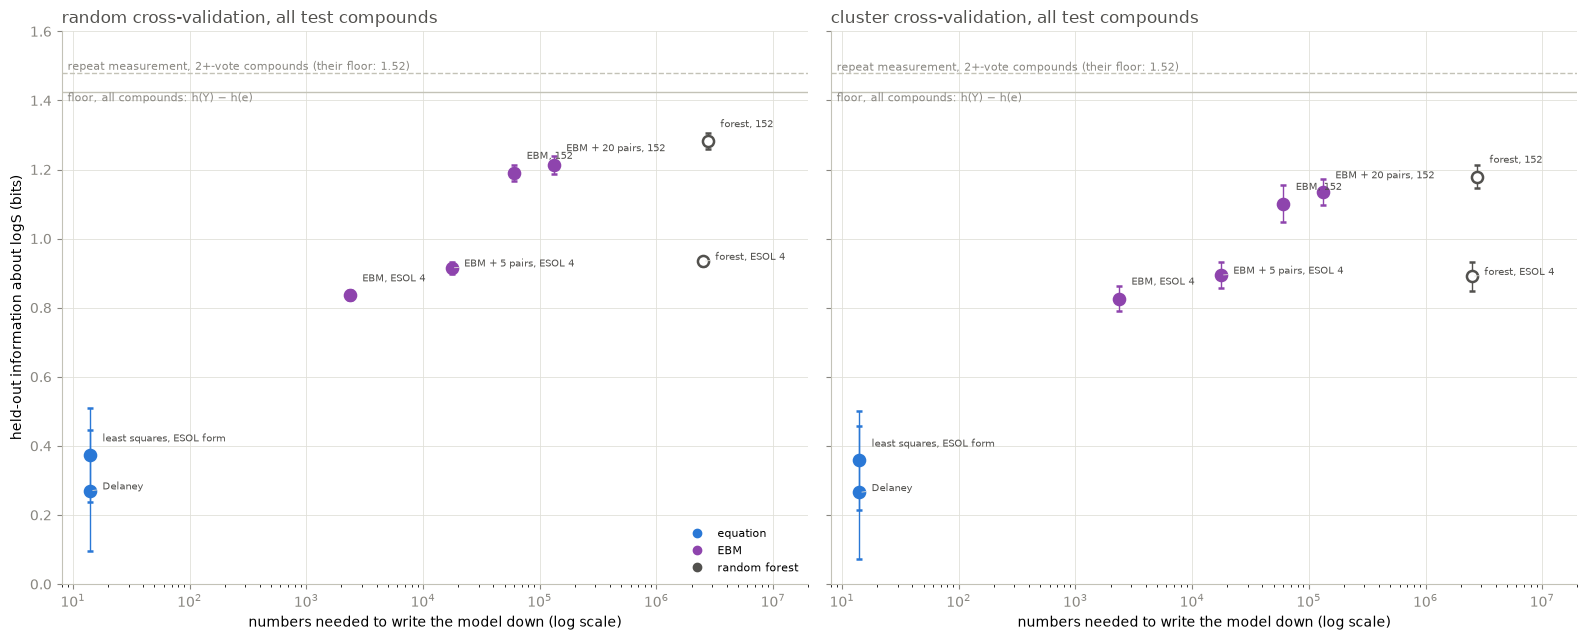

In [6]:
FAMILY_COLORS = {"equation": "#2a78d6", "EBM": "#8e44ad", "random forest": "#52514e"}
SHORT = {"Delaney's equation (published)": "Delaney", "least squares refit of ESOL's form": "least squares, ESOL form",
         "EBM, main effects, ESOL (4)": "EBM, ESOL 4", "EBM, 5 pairs, ESOL (4)": "EBM + 5 pairs, ESOL 4", "EBM, main effects, RDKit, one per group (152)": "EBM, 152",
         "EBM, 20 pairs, RDKit, one per group (152)": "EBM + 20 pairs, 152", "random forest, RDKit, one per group (152)": "forest, 152", "random forest, ESOL (4)": "forest, ESOL 4"}
SUBSET = "all test compounds"

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
for ax, scheme in zip(axes, ["random cross-validation", "cluster cross-validation"]):
    d = front[(front["scheme"] == scheme) & (front["subset"] == SUBSET)].copy()
    d["decade"] = np.floor(np.log10(d["numbers to write it down"])).astype(int)
    d["stack"] = d.groupby("decade")["information (bits)"].rank(ascending=False).astype(int) - 1
    for _, r in d.iterrows():
        color = FAMILY_COLORS[r["family"]]
        ax.errorbar(r["numbers to write it down"], r["information (bits)"], yerr=r["spread"], fmt="o", ms=8, color=color,
                    mfc=color if r["readable"] else "white", mew=1.8, ecolor=color, elinewidth=1, capsize=2)
        ax.annotate(SHORT.get(r["model"], r["model"]), (r["numbers to write it down"], r["information (bits)"]), xytext=(9, 10 - 9 * r["stack"]),
                    textcoords="offset points", fontsize=7.5, color=INK, arrowprops=dict(arrowstyle="-", color=GRID_C, lw=0.6) if r["stack"] else None)
    ax.axhline(BENCHMARK[scheme], color=AXIS, lw=1, ls="--")
    ax.text(9, BENCHMARK[scheme], f"repeat measurement, 2+-vote compounds (their floor: {FLOOR_REPEATED:.2f})", color=MUTED, fontsize=8, va="bottom", ha="left")
    ax.axhline(FLOOR, color=AXIS, lw=1)
    ax.text(9, FLOOR, "floor, all compounds: h(Y) − h(e)", color=MUTED, fontsize=8, va="top", ha="left")
    ax.set_xscale("log")
    ax.set_xlim(8, 2e7)
    ax.set_ylim(0, 1.6)
    ax.set_title(f"{scheme}, {SUBSET}", loc="left", color=INK)
    ax.set_xlabel("numbers needed to write the model down (log scale)")
    style(ax)
axes[0].set_ylabel("held-out information about logS (bits)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, mfc=c, label=f) for f, c in FAMILY_COLORS.items()]
axes[0].legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()

## Error bars

What each model would quote with a prediction: its calibrated $\tau$ and $\varepsilon$ (median over the random splits), the half-widths of its predictive density's central 50% and 90% intervals, and the share of held-out votes that actually fell inside them. The first row is measurement noise alone — the bar a perfect model would quote. The figure draws the predictive densities, and then one model's held-out predictions against the measured votes with its 90% band.

,τ (logS),ε,50% half-width (logS),90% half-width (logS),RMSE (logS),inside 50% (%),inside 90% (%)
model,,,,,,,
measurement noise alone,0.00,0.00,0.43,1.48,NaN,NaN,NaN
Delaney's equation (published),0.80,0.20,0.85,2.52,2.07,48.88,88.98
least squares refit of ESOL's form,1.20,0.10,1.02,2.67,1.78,49.97,90.13
"EBM, main effects, ESOL (4)",0.80,0.10,0.79,2.25,1.40,50.18,90.30
"EBM, 5 pairs, ESOL (4)",0.60,0.10,0.68,2.09,1.34,50.32,89.51
"random forest, ESOL (4)",0.50,0.15,0.66,2.22,1.36,50.34,90.35
"EBM, main effects, RDKit, one per group (152)",0.40,0.05,0.56,1.80,1.13,50.37,89.68
"EBM, 20 pairs, RDKit, one per group (152)",0.35,0.05,0.54,1.77,1.13,49.83,89.99
"random forest, RDKit, one per group (152)",0.30,0.05,0.52,1.75,1.09,50.68,90.06


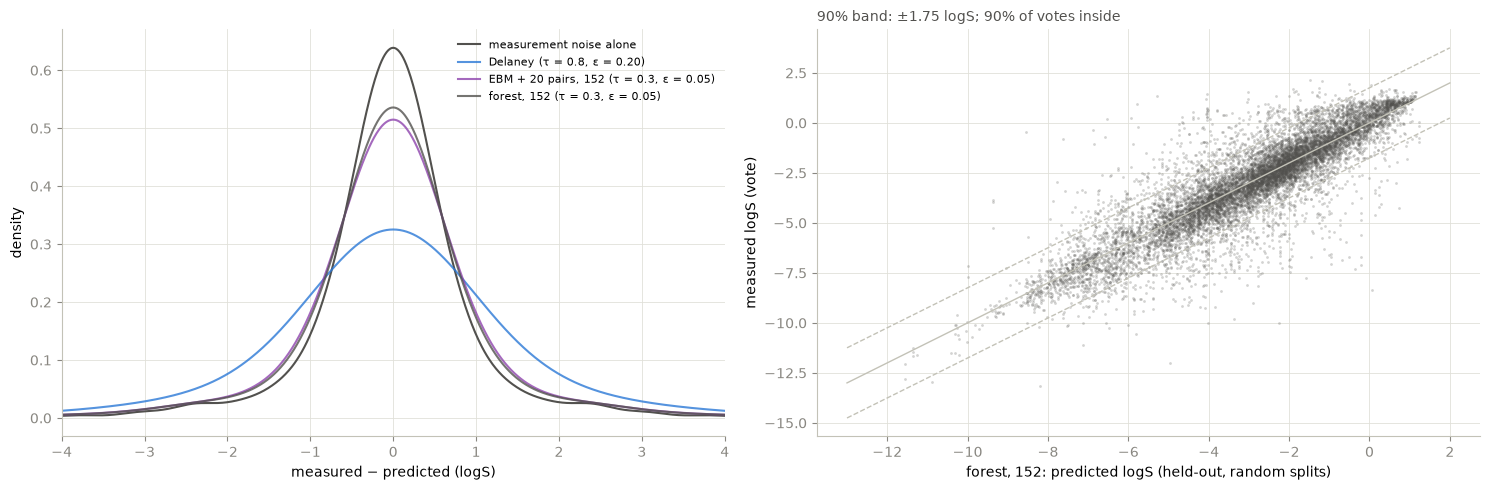

In [7]:
random_cv = held_out[(held_out["scheme"] == "random cross-validation") & (held_out["subset"] == "all test compounds")]
chosen = random_cv.groupby("predictor", sort=False)[["τ (logS)", "ε"]].median()
bars = pd.DataFrame(
    [{"model": "measurement noise alone", "τ (logS)": 0.0, "ε": 0.0, "50% half-width (logS)": noise.interval(0, 0, 0.5), "90% half-width (logS)": noise.interval(0, 0, 0.9)}]
    + [{"model": name, "τ (logS)": t, "ε": e, "50% half-width (logS)": noise.interval(t, e, 0.5), "90% half-width (logS)": noise.interval(t, e, 0.9),
        "RMSE (logS)": random_cv[random_cv["predictor"] == name]["RMSE (logS)"].mean(),
        "inside 50% (%)": random_cv[random_cv["predictor"] == name]["inside 50% interval (%)"].mean(),
        "inside 90% (%)": random_cv[random_cv["predictor"] == name]["inside 90% interval (%)"].mean()}
       for name, (t, e) in chosen.iterrows()]
).set_index("model")
display(bars.round(2))

SHOW = ["Delaney's equation (published)", "EBM, 20 pairs, RDKit, one per group (152)", "random forest, RDKit, one per group (152)"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(GRID, noise.predictive(0, 0), color=INK, lw=1.5, label="measurement noise alone")
for name in SHOW:
    t, e = chosen.loc[name]
    ax.plot(GRID, noise.predictive(t, e), color=FAMILY_COLORS[FAMILY[name]], lw=1.5, alpha=0.8, label=f"{SHORT[name]} (τ = {t:.1f}, ε = {e:.2f})")
ax.set_xlim(-4, 4)
ax.set_xlabel("measured − predicted (logS)")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8)
style(ax)

ax, name = axes[1], SHOW[-1]
t, e = chosen.loc[name]
half = noise.interval(t, e, 0.9)
pts = []
for split in CV_SPLITS:
    test = sides(split)[2][compound]
    pts.append(pd.DataFrame({"measured": y[test], "predicted": predictions[name, split][compound[test]]}))
pts = pd.concat(pts)
ax.scatter(pts["predicted"], pts["measured"], s=4, color=INK, alpha=0.25, lw=0)
line = np.array([-13, 2])
ax.plot(line, line, color=AXIS, lw=1)
ax.plot(line, line + half, color=AXIS, lw=1, ls="--")
ax.plot(line, line - half, color=AXIS, lw=1, ls="--")
ax.set_xlabel(f"{SHORT[name]}: predicted logS (held-out, random splits)")
ax.set_ylabel("measured logS (vote)")
ax.set_title(f"90% band: ±{half:.2f} logS; {bars.loc[name, 'inside 90% (%)']:.0f}% of votes inside", loc="left", color=INK, fontsize=10)
style(ax)
fig.tight_layout()

## Reading

1. **The ceiling is clean.** On the tiers the forest scored 105% of the repeat benchmark and the benchmark itself was not the limit, so there was no honest "how far from perfect" number. Here the floor is $h(Y) - h(e) = 1.42$ bits, the repeat measurement reaches 97% of its own floor, and the best model reaches 90% on familiar chemistry and 83% on unfamiliar. Those are the two numbers this notebook was built to produce.

2. **The error bar.** A measurement's own central 90% interval is ±1.48 logS (50%: ±0.43). The forest's calibrated predictive density is ±1.75 logS (50%: ±0.52) — about 20% wider than a measurement — and the additive model on the same descriptors ±1.77. So the best models' error bars are mostly measurement noise: of the forest's 1.09-logS RMSE, the noise accounts for the larger part. The bars are verified, not assumed: 50% and 90% of held-out votes fall inside them on random and cluster splits.

3. **The readable front keeps its shape.** Additive models reach 85% of the floor at a few hundred thousand numbers; the forest adds 0.07 bits for twenty times the length. The equations are the one family that moved: a line of 14 numbers carries 0.3–0.4 bits of a possible 1.42 on this axis, against 0.45–0.6 of a possible 0.96 on the tiers. Tiers made a short equation look better than it is, by not charging for how far it misses.

4. **What the tiers cost.** The same forest, same splits, same votes: 1.01 bits about a four-way label whose repeat benchmark is 0.96, or 1.28 bits about the value whose floor is 1.42. The 0.5 bits the discretization discarded were real.

Left for later: PySR's equations and the sparse trees (GOSDT and CORELS are classifiers; a regression tree would need a different solver) on this axis, and a heavier-tailed model error than $\mathcal{N}(0,\tau^2)$ for the learned splits, where the Gaussian widening under-covers.